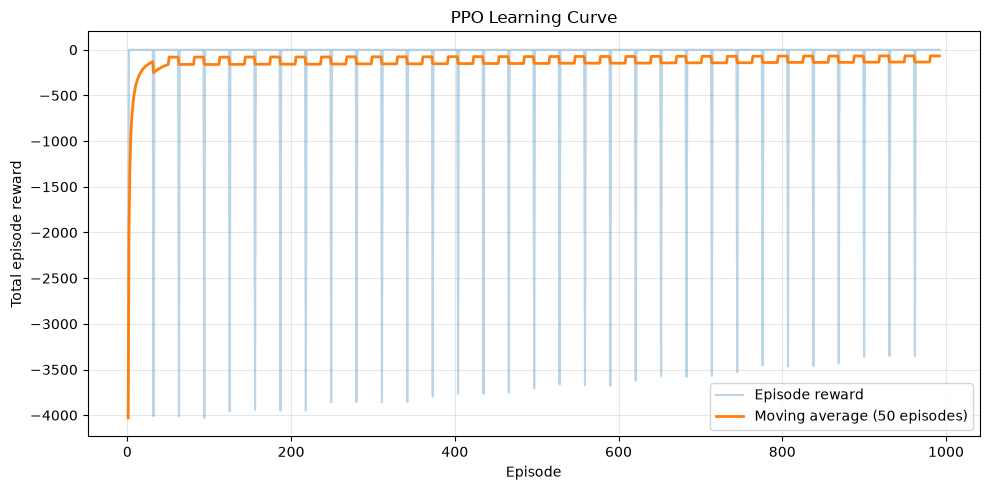

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Load training history
df = pd.read_csv("ppo_learning_curve_2.csv")

# Moving average
window = 50

df["reward_smooth"] = (
    df["episode_reward"]
    .rolling(window=window, min_periods=1)
    .mean()
)

# Plot
plt.figure(figsize=(10, 5))

plt.plot(
    df["episode"],
    df["episode_reward"],
    alpha=0.3,
    label="Episode reward"
)

plt.plot(
    df["episode"],
    df["reward_smooth"],
    linewidth=2,
    label=f"Moving average ({window} episodes)"
)

plt.xlabel("Episode")
plt.ylabel("Total episode reward")
plt.title("PPO Learning Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


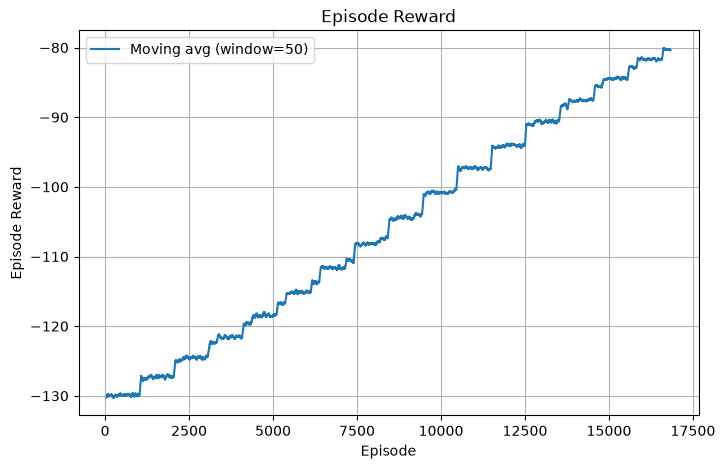

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def moving_average(values, window):
    weights = np.repeat(1.0, window) / window
    return np.convolve(values, weights, "valid")


def plot_reward(csv_path, window=50, title="Episode Reward"):
    df = pd.read_csv(csv_path, skiprows=1)
    rewards = df["r"].values
    episodes = np.arange(1, len(rewards) + 1)

    smooth = moving_average(rewards, window)
    ep_smooth = episodes[len(episodes) - len(smooth):]

    plt.figure(figsize=(8, 5))
    # plt.plot(episodes, rewards, alpha=0.3, label="Raw")
    plt.plot(ep_smooth, smooth, label=f"Moving avg (window={window})")
    # plt.axhline(113, color="red", linestyle="--", alpha=0.5, label="Step cap (113)")
    plt.xlabel("Episode")
    plt.ylabel("Episode Reward")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_reward("logs/vec_monitor.monitor.csv", window=50)

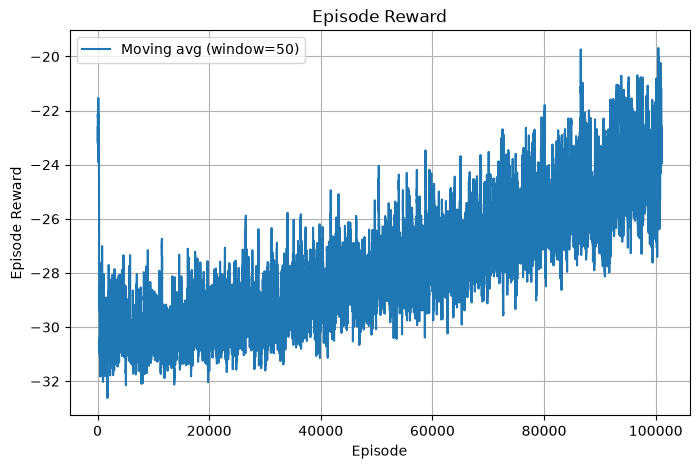

In [37]:
plot_reward("logs/vec_monitor_1.monitor.csv", window=50)

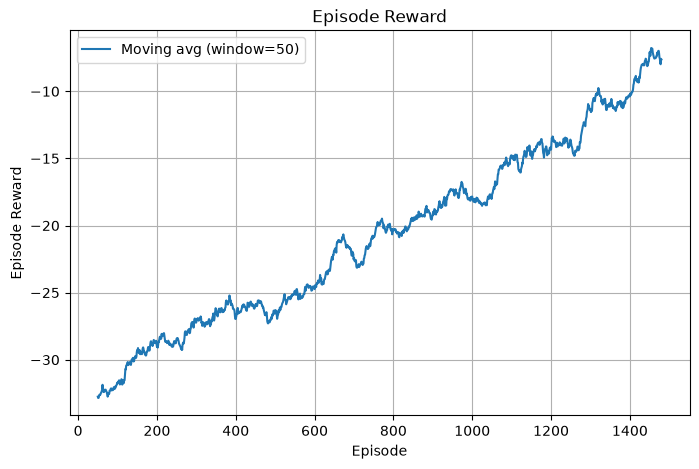

In [38]:
plot_reward("logs/monitor_3.monitor.csv", window=50)

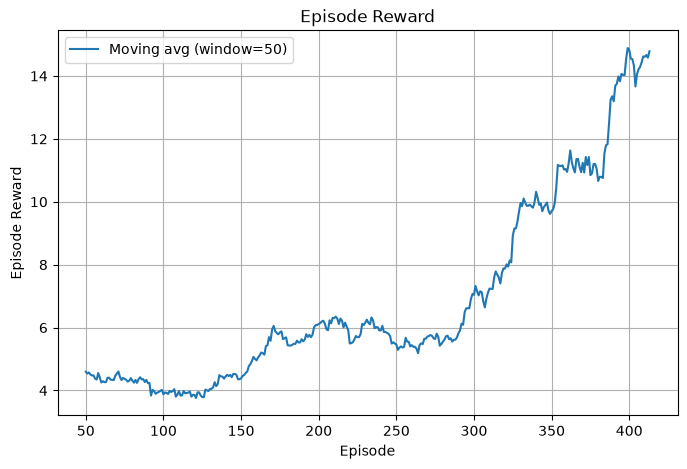

In [39]:
plot_reward("logs/monitor_4.monitor.csv", window=50)

In [7]:
import csv
import gpytorch
import gymnasium as gym
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import random
import re
import torch
import warnings

from collections import deque
from gymnasium.utils.env_checker import check_env
from scipy.stats import entropy
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.metrics import mean_squared_error, r2_score, pairwise_distances
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import cross_val_score, cross_val_predict
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy
from stable_baselines3.common.monitor import load_results as _lr
from stable_baselines3 import PPO
from typing import Optional

In [8]:
class CRDADataGenerator(gym.Env):
    metadata = {"render_modes":[]}

    def __init__(self,
                 X: np.ndarray,
                 y: np.ndarray,
                 model: BaseEstimator,
                 residual: np.ndarray,
                 MSE: float,
                 div_low: float,
                 div_high: float,
                 reward_clip:float=1.0,
                 verbose: bool=False,
                 cv:int=10,
                 history_length:int=5,
                 similarity_threshold:float=0.95,
                 bins:int=10
                 ):
        super().__init__()

        self.X = np.asarray(X, dtype=np.float32)
        self.y = np.asarray(y, dtype=np.float32)

        self.residual = np.asarray(residual, dtype=np.float32)

        self.dataset_length = self.X.shape[0]
        self.bins = bins
        self.model = model
        self.MSE = MSE
        self.entropy = self._avg_entropy_cal(self.X, self.bins)

        self.current_step = 0
        self.div_low = div_low
        self.div_high = div_high

        self.history_length = history_length
        self.n_features = self.X.shape[-1]

        self.reward_clip = reward_clip
        self.verbose = verbose
        self.cv = cv
        self.similarity_threshold = similarity_threshold

        # For Reset
        self._datapoints_init = self.X.copy()
        self._targets_init = self.y.copy()
        self._residual_init = self.residual.copy()
        self._MSE_init = self.MSE
        self._entropy_init = self.entropy
        self._init_params = self.model.get_params()

        # Action space
        self.action_space = gym.spaces.Box(
            low=-1.0, high=1.0, shape=(self.n_features,), dtype=np.float32
        )

        # Observation space
        self.observation_space = gym.spaces.Dict({
            "mse": gym.spaces.Box(low=0.0, high=np.inf, shape=(1,), dtype=np.float32),
            "entropy": gym.spaces.Box(low=0.0, high=np.inf, shape=(1,), dtype=np.float32),
            "diversity": gym.spaces.Box(low=0.0, high=np.inf, shape=(1,), dtype=np.float32),
            "corr_res": gym.spaces.Box(low=-1.0, high=1.0, shape=(1,), dtype=np.float32),
            "corr_feat_w_y": gym.spaces.Box(low=-1.0, high=1.0, shape=(self.n_features,), dtype=np.float32),
            "action_history": gym.spaces.Box(low=-1.0, high=1.0, shape=(self.history_length, self.n_features), dtype=np.float32),
            "feat_mean": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_mean": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_std": gym.spaces.Box(low=0.0, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_std": gym.spaces.Box(low=0.0, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_min": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_min": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_max": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_max": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_median": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_median": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_95th_percentile": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_95th_percentile": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_5th_percentile": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self .n_features,), dtype=np.float32),
            "target_5th_percentile": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_skewness": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_skewness": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            "feat_kurtosis": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(self.n_features,), dtype=np.float32),
            "target_kurtosis": gym.spaces.Box(low=-np.inf, high=np.inf, shape=(1,), dtype=np.float32),
            })

        self.state = None

    def _avg_entropy_cal(self, X: np.ndarray, bins: int) -> float:
        """Calculate the average entropy of the features in X."""
        entropies = []
        for i in range(X.shape[1]):
            hist, _ = np.histogram(X[:, i], bins=bins, density=True)
            hist = hist[hist > 0]  # Remove zero entries to avoid log(0)
            entropies.append(entropy(hist))
        return np.mean(entropies)

    def _get_observation(self, MSE: float, X: np.ndarray, y: np.ndarray, residual: np.ndarray, entropy: float, action_history: deque) -> dict:
        """Construct the observation dictionary."""
        obs = {
            "mse": np.array([MSE], dtype=np.float32),
            "entropy": np.array([entropy], dtype=np.float32),
            "diversity": np.array([self._calculate_diversity(X)], dtype=np.float32),
            "corr_res": np.array([np.corrcoef(residual, y)[0, 1]], dtype=np.float32) if len(residual) > 1 else np.array([0.0], dtype=np.float32),
            "corr_feat_w_y": np.array([np.corrcoef(X[:, i], y)[0, 1] for i in range(X.shape[1])], dtype=np.float32),
            "action_history": np.array(action_history, dtype=np.float32),
            "feat_mean": np.array(np.mean(X, axis=0), dtype=np.float32),
            "target_mean": np.array([np.mean(y)], dtype=np.float32),
            "feat_std": np.array(np.std(X, axis=0), dtype=np.float32),
            "target_std": np.array([np.std(y)], dtype=np.float32),
            "feat_min": np.array(np.min(X, axis=0), dtype=np.float32),
            "target_min": np.array([np.min(y)], dtype=np.float32),
            "feat_max": np.array(np.max(X, axis=0), dtype=np.float32),
            "target_max": np.array(np.max(y), dtype=np.float32).reshape(1, ),
            "feat_median": np.array(np.median(X, axis=0), dtype=np.float32),
            "target_median": np.array(np.median(y), dtype=np.float32).reshape(1, ),
            "feat_95th_percentile": np.array(np.percentile(X, 95, axis=0), dtype=np.float32),
            "target_95th_percentile": np.array(np.percentile(y, 95), dtype=np.float32).reshape(1, ),
            "feat_5th_percentile": np.array(np.percentile(X, 5, axis=0), dtype=np.float32),
            "target_5th_percentile": np.array(np.percentile(y, 5), dtype=np.float32).reshape(1, ),
            "feat_skewness": np.array([np.mean(((X[:, i] - np.mean(X[:, i])) / np.std(X[:, i]))**3) for i in range(X.shape[1])], dtype=np.float32),
            "target_skewness": np.array([np.mean(((y - np.mean(y)) / np.std(y))**3)], dtype=np.float32),
            "feat_kurtosis": np.array([np.mean(((X[:, i] - np.mean(X[:, i])) / np.std(X[:, i]))**4) - 3 for i in range(X.shape[1])], dtype=np.float32),
            "target_kurtosis": np.array([np.mean(((y - np.mean(y)) / np.std(y))**4) - 3], dtype=np.float32),
        }
        return obs

    def reset(self, seed: Optional[int] = None, options: Optional[dict] = None):
        super().reset(seed=seed, options=options)

        if seed is not None:
            np.random.seed(seed)
            random.seed(seed)
            torch.manual_seed(seed)

        self.X = self._datapoints_init.copy()
        self.y = self._targets_init.copy()
        self.residual = self._residual_init.copy()
        self.MSE = self._MSE_init
        self.entropy = self._entropy_init

        self.current_step = 0
        self.action_history = deque(maxlen=self.history_length)

        # Initialize action history with zeros
        for _ in range(self.history_length):
            self.action_history.append(np.zeros(self.n_features, dtype=np.float32))
        
        # print(f"Shape of self.action_history: {np.asarray(self.action_history).shape}")

        self.model.set_params(**self._init_params)

        # Update state
        obs = self._get_observation(self.MSE, self.X, self.y, self.residual, self.entropy, self.action_history)

        self.state = self._get_state(self.X, self.y)

        return obs, {}

    def _get_state(self, X: np.ndarray, y: np.ndarray) -> dict:
        """Construct the state dictionary."""
        state = {
            "feat_mean": np.mean(X, axis=0).astype(np.float32),
            "target_mean": np.mean(y).astype(np.float32),
            "feat_std": np.std(X, axis=0).astype(np.float32),
            "target_std": np.std(y).astype(np.float32),
            "feat_min": np.min(X, axis=0).astype(np.float32),
            "target_min": np.min(y).astype(np.float32),
            "feat_max": np.max(X, axis=0).astype(np.float32),
            "target_max": np.max(y).astype(np.float32),
            "feat_median": np.median(X, axis=0).astype(np.float32),
            "target_median": np.median(y).astype(np.float32),
            "feat_95th_percentile": np.percentile(X, 95, axis=0).astype(np.float32),
            "target_95th_percentile": np.percentile(y, 95).astype(np.float32),
            "feat_5th_percentile": np.percentile(X, 5, axis=0).astype(np.float32),
            "target_5th_percentile": np.percentile(y, 5).astype(np.float32),
            "feat_skewness": np.array([np.mean(((X[:, i] - np.mean(X[:, i])) / np.std(X[:, i]))**3) for i in range(X.shape[1])], dtype=np.float32),
            "target_skewness": np.array([np.mean(((y - np.mean(y)) / np.std(y))**3)], dtype=np.float32),
            "feat_kurtosis": np.array([np.mean(((X[:, i] - np.mean(X[:, i])) / np.std(X[:, i]))**4) - 3 for i in range(X.shape[1])], dtype=np.float32),
            "target_kurtosis": np.array([np.mean(((y - np.mean(y)) / np.std(y))**4) - 3], dtype=np.float32),
        }
        return state

    def _calculate_diversity(self, X: np.ndarray) -> float:
        """Calculate the diversity of the dataset based on pairwise distances."""
        if X.shape[0] < 2:
            return 0.0
        pairwise_dist = pairwise_distances(X)
        diversity = np.mean(pairwise_dist)
        return diversity

    def step(self, action: np.ndarray):
        raw_action = np.clip(action, -1.0, 1.0)

        candidate = self._get_candidate_point(raw_action)

        invalid_action = False

        self.action_history.append(raw_action)

        y_label = self.model.predict(candidate.reshape(1, -1)).item()
        similarity = cosine_similarity(candidate.reshape(1, -1), self.X).max()

        if similarity > self.similarity_threshold:
            invalid_action = True
            reward = -1.0
            done = False
            info = {"invalid_action": invalid_action, "reason": "Similarity threshold exceeded."}
            obs = self._get_observation(self.MSE, self.X, self.y, self.residual, self.entropy, self.action_history)
            return obs, reward, done, False, info

        nn_idx = int(np.argmax(similarity))
        y_label += self.residual[nn_idx]

        X_new = np.vstack([self.X, candidate])
        y_new = np.append(self.y, y_label)

        eval_model = clone(self.model)
        y_pred = cross_val_predict(eval_model, X_new, y_new, cv=self.cv)
        MSE_new = mean_squared_error(y_new, y_pred)
        residual_new = y_new - y_pred
        entropy_mean = self._avg_entropy_cal(X_new, self.bins)

        if invalid_action:
            reward = -self.reward_clip
        elif entropy_mean > self.entropy:
            self.entropy = entropy_mean
            self.X = X_new
            self.y = y_new
            self.residual = residual_new
            self.MSE = MSE_new
            log_r2 = self._log_r_score_cal(y_new, y_pred)
            reward = log_r2 + 0.5*self.entropy
        else:
            reward = (self.entropy - entropy_mean)

        truncated = (len(self.X) >= int(1.2 * self.dataset_length) or self.current_step >= 1000)
        terminated = False

        obs = self._get_observation(self.MSE, self.X, self.y, self.residual, self.entropy, self.action_history)
        info = {"invalid_action": invalid_action, "similarity": similarity, "entropy": self.entropy, "MSE": self.MSE}
        return obs, reward, terminated, truncated, info

    def _get_candidate_point(self, action: np.ndarray) -> np.ndarray:
        """Generate a candidate point based on the action."""
        # Scale action to the feature space
        self.current_step += 1
        scaled_action = (action + 1) / 2  # Scale from [-1, 1] to [0, 1]
        weights = scaled_action / np.sum(scaled_action)  # Normalize to sum to 1

        return weights.astype(np.float32)

    def _log_r_score_cal(self, y_true: np.ndarray, y_pred: np.ndarray) -> float:
        """Calculate the log of the R^2 score."""
        r2 = r2_score(y_true, y_pred)
        return np.log(1/np.maximum(1.0 - r2, 1e-6))  # Add a small value to avoid log(0)


In [9]:
with open(file="steels_yield.json") as file:
    data = json.load(file)

In [10]:
my_data = {}
for i in range(len(data['columns'])):
    my_data[data['columns'][i]] = []
    for j in range(len(data['data'])):
        my_data[data['columns'][i]].append(data['data'][j][i])

In [11]:
my_data['split_composition'] = []
for composition in my_data['composition']:
    matches = re.findall(r'([A-Z][a-z]?)(\d*\.?\d+)', composition)
    my_data['split_composition'].append({element: float(value) for element, value in matches})

In [12]:
key_count = []
for key in my_data['split_composition']:
    key_count.append(key.keys())
keys = list(max(key_count))

In [13]:
composition_dict = {}

for key in keys:
    composition_dict[key] = []
    for comp in my_data['split_composition']:
        if key in list(comp.keys()):
            composition_dict[key].append(comp[key])
        else:
            composition_dict[key].append(0)

df = pd.DataFrame(data=composition_dict)
df_targets = pd.DataFrame(my_data['yield strength'], columns=["yield_strength"])
df_final = pd.concat([df, df_targets], axis=1)

In [14]:
df_final

,Fe,C,Mn,Si,Cr,Ni,Mo,V,Nb,Co,W,Al,Ti,yield_strength
0,0.620,0.000953,0.000521,0.001020,0.000110,0.192000,0.01760,0.000112,0.000062,0.146000,0.00000,0.003180,0.01850,2411.5
1,0.623,0.008540,0.000104,0.000203,0.147000,0.000097,0.01790,0.005150,0.000061,0.188000,0.00729,0.000845,0.00000,1123.1
2,0.625,0.000000,0.000102,0.000200,0.093600,0.129000,0.00480,0.000110,0.000060,0.132000,0.00000,0.008120,0.00669,1736.3
3,0.634,0.000478,0.000523,0.001020,0.000111,0.173000,0.02370,0.000113,0.000062,0.146000,0.00000,0.002770,0.01760,2487.3
4,0.636,0.000474,0.000518,0.001010,0.000109,0.188000,0.00860,0.000112,0.000061,0.144000,0.00000,0.002740,0.01840,2249.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,0.823,0.017600,0.001830,0.000198,0.077900,0.000095,0.02190,0.010500,0.000060,0.046300,0.00000,0.000620,0.00000,1722.5
308,0.823,0.000000,0.000618,0.001010,0.056100,0.098400,0.01890,0.000111,0.000061,0.000096,0.00000,0.000629,0.00106,1019.0
309,0.825,0.017400,0.001750,0.000201,0.056500,0.000096,0.03440,0.011600,0.005540,0.046800,0.00000,0.000628,0.00000,1860.3
310,0.858,0.019100,0.001940,0.000199,0.075300,0.000095,0.03410,0.010100,0.000060,0.000190,0.00000,0.000623,0.00000,1812.1


In [15]:
X = np.array(df_final.drop(columns=["yield_strength"]))
y = np.log(np.array(df_final["yield_strength"]))

In [16]:
class ARDExactGPModel_Dense(gpytorch.models.ExactGP):
    """Gaussian Process Architecture for Dense Datasets (i.e Composition datasets)

        Params:
            - train_x: train features
            - train_y: train labels
            - likelihood: likelihood of Gaussian Process  
        """
    def __init__(self, 
                 train_x: torch.Tensor, 
                 train_y: torch.Tensor, 
                 likelihood: gpytorch.likelihoods):
        super().__init__(train_x, train_y, likelihood)

        self.mean_module = gpytorch.means.ConstantMean()

        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel(
                ard_num_dims=train_x.shape[1]
            )
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

class GPRegressor(BaseEstimator, RegressorMixin):
    """Scikit-learn wrapper around ARDExactGPModel_Dense."""

    def __init__(self, lr=0.1, training_iter=100, device='cpu'):
        self.lr = lr 
        self.training_iter = training_iter
        self.device = device

    def fit(self, X, y):
        # Convert to tensors (sklearn passes numpy arrays)
        train_x = torch.as_tensor(np.asarray(X), dtype=torch.float32, device=self.device)
        train_y = torch.as_tensor(np.asarray(y), dtype=torch.float32, device=self.device).ravel()

        # Fresh likelihood + model for THIS fold
        self.likelihood_ = gpytorch.likelihoods.GaussianLikelihood().to(self.device)
        self.model_ = ARDExactGPModel_Dense(train_x, train_y, self.likelihood_).to(self.device)

        self.model_.train()
        self.likelihood_.train()

        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr)
        mll = gpytorch.mlls.ExactMarginalLogLikelihood(self.likelihood_, self.model_)

        for _ in range(self.training_iter):
            optimizer.zero_grad()
            output = self.model_(train_x)
            loss = -mll(output, train_y)
            loss.backward()
            optimizer.step()

        return self

    def predict(self, X):
        test_x = torch.as_tensor(np.asarray(X), dtype=torch.float32, device=self.device)

        self.model_.eval()
        self.likelihood_.eval()

        with torch.no_grad():
            preds = self.likelihood_(self.model_(test_x))
            mean = preds.mean

        return mean.cpu().numpy()

In [17]:
model = GPRegressor(lr=0.1, training_iter=100, device='cpu')
model.fit(X, y)

,lr,0.1
,training_iter,100
,device,'cpu'
Name,Type,Value
likelihood_,GaussianLikelihood,GaussianLikel...000E-04) ) )
model_,ARDExactGPModel_Dense,ARDExactGPMod...sitive() ) )


In [18]:
mean_squared_error(y, model.predict(X))

/home/bandarua/.conda/envs/RL/lib/python3.14/site-packages/gpytorch/models/exact_gp.py:284: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


0.0031181315285044873

In [19]:
mse = -cross_val_score(model, X, y, cv=10, scoring='neg_mean_squared_error', n_jobs=-1).mean()
residual = y - model.predict(X)

/home/bandarua/.conda/envs/RL/lib/python3.14/site-packages/gpytorch/models/exact_gp.py:284: GPInputWarning: The input matches the stored training data. Did you forget to call model.train()?
  warnings.warn(


In [20]:
residual_mean = residual.mean()
residual_std = residual.std()
factor = pd.DataFrame(y).skew().to_numpy().item()
div_low = factor*(residual_mean - residual_std).item()
div_high = factor*(residual_mean + residual_std).item()

In [21]:
gym.register(
        id="gymnasium_env/CRDADataGen-v1",
        entry_point=CRDADataGenerator,
        # max_episode_steps=500,  # Prevent infinite episodes
    )

In [22]:
env = gym.make("gymnasium_env/CRDADataGen-v1",
               X=X,
               y=y,
               model=model,
               residual=residual,
               MSE=mse,
               div_low=div_low,
               div_high=div_high,
               reward_clip=1.0,
               verbose=False,
               cv=5)

In [23]:
model = PPO.load("NEW_DATA_GENERATOR_PPO_MODEL")

synthetic_rows = []

obs, info = env.reset(seed=42)

for i in range(3):
    print(f"\nStep {i + 1}")

    # Record dataset size before proposing a candidate
    n_before = len(env.unwrapped.X)

    # Predict an action
    action, _states = model.predict(obs, deterministic=True)

    print("Proposed action:", action)

    # Execute the action
    obs, reward, terminated, truncated, info = env.step(action)

    # Check whether the dataset grew
    n_after = len(env.unwrapped.X)
    accepted = n_after > n_before

    print("Reward:", reward)
    print("Accepted:", accepted)
    print("Dataset size before:", n_before)
    print("Dataset size after:", n_after)
    print("Next observation:", obs)

    if accepted:
        synthetic_rows.append(action.copy())

    if terminated or truncated:
        print("Episode ended.")
        break

print("\nNumber of accepted actions:", len(synthetic_rows))


Step 1
Proposed action: [-1.          1.          0.32786366 -0.7591341  -1.         -1.
  1.         -0.37583962 -1.         -1.         -0.8315198   1.
  1.        ]
Reward: 0.4417807115239787
Accepted: False
Dataset size before: 312
Dataset size after: 312
Next observation: {'mse': array([0.02100841], dtype=float32), 'entropy': array([1.1920288], dtype=float32), 'diversity': array([0.15088758], dtype=float32), 'corr_res': array([0.3646272], dtype=float32), 'corr_feat_w_y': array([-0.12584282,  0.1956934 , -0.18789665, -0.13253458, -0.38029566,
        0.21319997,  0.05049581,  0.22074471,  0.03490483,  0.20648225,
       -0.02448595, -0.02575385,  0.46199235], dtype=float32), 'action_history': array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.  

In [ ]:
env.observation_space

In [ ]:
ppo_model.observation_space

In [ ]:
Dict('action_history': Box(-1.0, 1.0, (5, 13), float32), 
     'corr_feat_w_y': Box(-1.0, 1.0, (13,), float32), 
     'corr_res': Box(-1.0, 1.0, (1,), float32), 
     'diversity': Box(0.0, inf, (1,), float32), 
     'entropy': Box(0.0, inf, (1,), float32), 
     'feat_5th_percentile': Box(-inf, inf, (13,), float32), 
     'feat_95th_percentile': Box(-inf, inf, (13,), float32), 
     'feat_kurtosis': Box(-inf, inf, (13,), float32), 
     'feat_max': Box(-inf, inf, (13,), float32), 
     'feat_mean': Box(-inf, inf, (13,), float32), 
     'feat_median': Box(-inf, inf, (13,), float32), 
     'feat_min': Box(-inf, inf, (13,), float32), 
     'feat_skewness': Box(-inf, inf, (13,), float32), 
     'feat_std': Box(0.0, inf, (13,), float32), 
     'mse': Box(0.0, inf, (1,), float32), 
     'target_5th_percentile': Box(-inf, inf, (1,), float32), 
     'target_95th_percentile': Box(-inf, inf, (1,), float32), 
     'target_kurtosis': Box(-inf, inf, (1,), float32), 
     'target_max': Box(-inf, inf, (1,), float32), 
     'target_mean': Box(-inf, inf, (1,), float32), 
     'target_median': Box(-inf, inf, (1,), float32), 
     'target_min': Box(-inf, inf, (1,), float32), 
     'target_skewness': Box(-inf, inf, (1,), float32), 
     'target_std': Box(0.0, inf, (1,), float32))


In [ ]:
Dict('action_history': Box(-1.0, 1.0, (5, 13), float32), 
     'corr_feat_w_y': Box(-1.0, 1.0, (13,), float32), 
     'corr_res': Box(-1.0, 1.0, (1,), float32), 
     'diversity': Box(0.0, inf, (1,), float32), 
     'entropy': Box(0.0, inf, (1,), float32), 
     'feat_5th_percentile': Box(-inf, inf, (13,), float32), 
     'feat_95th_percentile': Box(-inf, inf, (13,), float32), 
     'feat_kurtosis': Box(-inf, inf, (13,), float32), 
     'feat_max': Box(-inf, inf, (13,), float32), 
     'feat_mean': Box(-inf, inf, (13,), float32), 
     'feat_median': Box(-inf, inf, (13,), float32), 
     'feat_min': Box(-inf, inf, (13,), float32), 
     'feat_skewness': Box(-inf, inf, (13,), float32), 
     'feat_std': Box(0.0, inf, (13,), float32), 
     'mse': Box(0.0, inf, (1,), float32), 
     'target_5th_percentile': Box(-inf, inf, (1,), float32), 
     'target_95th_percentile': Box(-inf, inf, (1,), float32), 
     'target_kurtosis': Box(-inf, inf, (1,), float32), 
     'target_max': Box(-inf, inf, (1,), float32), 
     'target_mean': Box(-inf, inf, (1,), float32), 
     'target_median': Box(-inf, inf, (1,), float32), 
     'target_min': Box(-inf, inf, (1,), float32), 
     'target_skewness': Box(-inf, inf, (1,), float32), 
     'target_std': Box(0.0, inf, (1,), float32))

In [ ]:
print(type(obs), np.array(obs).shape)
print("Expected:", ppo_model.observation_space.shape)

In [ ]:
for k, v in obs.items():
    v = np.asarray(v)
    expected = env.observation_space[k].shape
    flag = "  <-- MISMATCH" if v.shape != expected else ""
    print(f"{k:28s} got {str(v.shape):12s} expected {expected}{flag}")
